# Sales Prediction Using Python

## 1. Project Overview

**Objective:** Predict product sales from advertising expenditure on TV, radio, and newspaper.

This is a **supervised regression** problem because the target (`sales`) is a continuous numerical value.

### Dataset columns
- `TV`: advertising expenditure on TV
- `radio`: advertising expenditure on radio
- `newspaper`: advertising expenditure on newspaper
- `sales`: target variable to predict
- `Unnamed: 0`: index-like identifier; not used as a predictor

### Workflow
1. Load and inspect the data
2. Perform exploratory data analysis (EDA)
3. Prepare features and target
4. Split into training and testing sets
5. Train and compare regression models
6. Tune a Decision Tree
7. Compare a Random Forest model
8. Select, evaluate, and save the final pipeline
9. Load the saved model and predict sales for new data

**Important:** Run this notebook from the project folder that contains `Advertising (1).csv`. The notebook saves `sales_prediction_pipeline.pkl` in the current working directory.

## 2. Import Libraries

Import the libraries used throughout the notebook in one place.

In [9]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 3. Load the Dataset

Read the CSV file into a Pandas DataFrame. If Python cannot find the file, check the current working directory and make sure the CSV filename matches.

In [10]:
print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

df = pd.read_csv("Advertising (1).csv")
df.head()

Current working directory: c:\Users\ACER\OIBSIP-GitHub\DataScience-Task5-SalesPrediction
Files in current directory: ['.gitignore', '.venv', 'Advertising (1).csv', 'app.py', 'sales_prediction.ipynb']


,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## 4. Inspect the Dataset

Check the number of rows and columns, data types, summary statistics, missing values, and duplicate rows.

In [11]:
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
df.info()

Dataset shape: (200, 5)

Column names: ['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [12]:
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [13]:
print("Missing values per column:")
display(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

Missing values per column:


Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

Number of duplicate rows: 0


### Handle duplicates and the index-like column

The original dataset has an `Unnamed: 0` column that acts like an identifier, not an advertising feature. We exclude it from modelling. Duplicate rows are checked before removing them; this code removes exact duplicate rows if any exist.

In [14]:
df = df.drop_duplicates().copy()
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Shape after cleanup:", df.shape)
print("Remaining columns:", df.columns.tolist())
df.head()

Shape after cleanup: (200, 4)
Remaining columns: ['TV', 'radio', 'newspaper', 'sales']


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the distributions of the variables and their relationships. Correlation describes association; it does not prove that advertising expenditure causes sales to change.

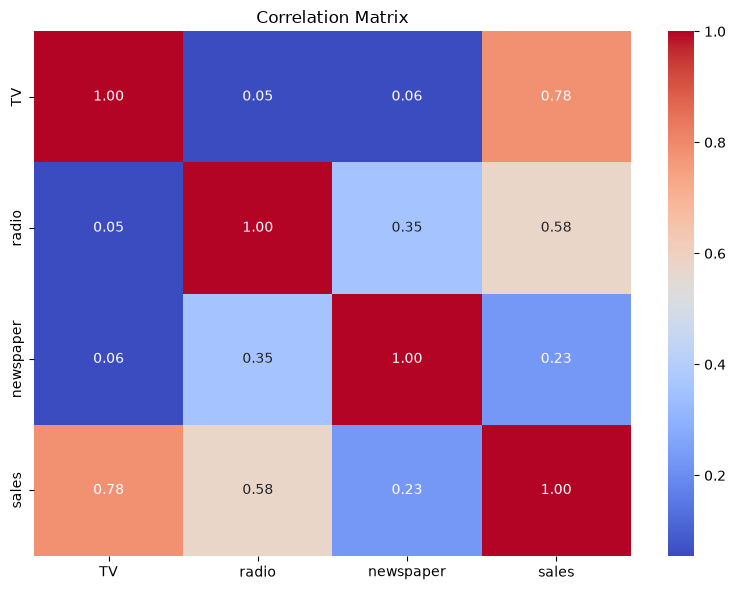

In [15]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

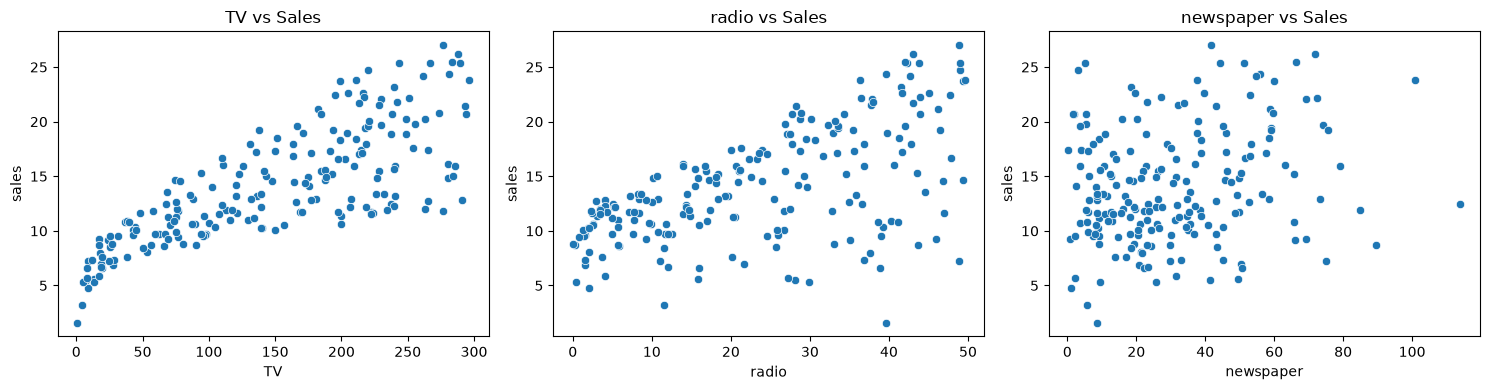

In [16]:
# Scatterplots show how each advertising channel relates to sales.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, ["TV", "radio", "newspaper"]):
    sns.scatterplot(data=df, x=feature, y="sales", ax=ax)
    ax.set_title(f"{feature} vs Sales")

plt.tight_layout()
plt.show()

### EDA notes

In the recorded analysis, TV advertising had the strongest positive correlation with sales (approximately 0.78 in the correlation matrix after excluding the identifier), followed by radio (approximately 0.58). Newspaper had a weaker positive correlation (approximately 0.23). These correlations are descriptive and do not establish causation.

## 6. Select Features and Target

`X` contains the three input features. `y` contains the sales value the model learns to predict.

In [17]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
display(y.head())

Features shape: (200, 3)
Target shape: (200,)


,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: sales, dtype: float64

## 7. Split into Training and Testing Sets

Use 80% of the data for training and 20% for testing. `random_state=42` makes the split reproducible. The test set is held aside to estimate performance on unseen rows.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 3)
X_test: (40, 3)
y_train: (160,)
y_test: (40,)


## 8. Helper Function for Evaluation

Use the same metrics for each model so the comparison is fair.

- **MAE:** average absolute prediction error; lower is better.
- **MSE:** average squared error; lower is better.
- **RMSE:** square root of MSE, expressed in sales units; lower is better.
- **R²:** proportion of target variation explained by the model on the evaluated data; higher is generally better.

In [19]:
def evaluate_regression(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "MAE": mean_absolute_error(y_eval, predictions),
        "MSE": mean_squared_error(y_eval, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_eval, predictions)),
        "R²": r2_score(y_eval, predictions),
    }

## 9. Train a Linear Regression Model

In [20]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_results = evaluate_regression(linear_model, X_test, y_test)
pd.Series(linear_results, name="Linear Regression").round(3)

MAE     1.461
MSE     3.174
RMSE    1.782
R²      0.899
Name: Linear Regression, dtype: float64

In [21]:
linear_predictions = linear_model.predict(X_test)

linear_comparison = pd.DataFrame({
    "Actual Sales": y_test.to_numpy(),
    "Predicted Sales": linear_predictions
})
linear_comparison.head(10).round(2)

,Actual Sales,Predicted Sales
0,16.9,16.41
1,22.4,20.89
2,21.4,21.55
3,7.3,10.61
4,24.7,22.11
5,12.6,13.11
6,22.3,21.06
7,8.4,7.46
8,11.5,13.61
9,14.9,15.16


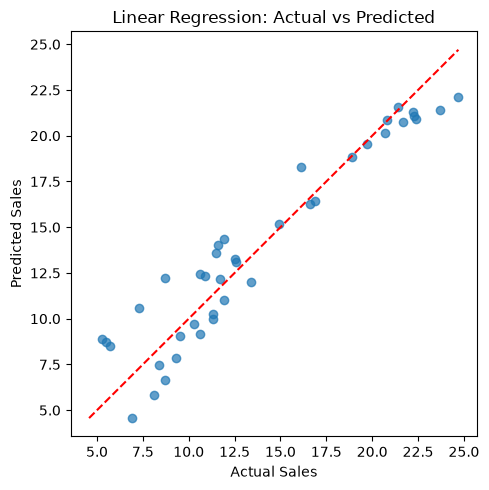

In [22]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, linear_predictions, alpha=0.7)
limits = [
    min(y_test.min(), linear_predictions.min()),
    max(y_test.max(), linear_predictions.max())
]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

## 10. Train a Decision Tree Regressor

A Decision Tree learns a series of feature-based splits. An unrestricted tree can fit the training data extremely closely, which may lead to overfitting.

In [23]:
decision_tree = DecisionTreeRegressor(random_state=42)
decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)
dt_results = evaluate_regression(decision_tree, X_test, y_test)

print("Training R²:", round(decision_tree.score(X_train, y_train), 3))
print("Testing R²:", round(dt_results["R²"], 3))
pd.Series(dt_results, name="Decision Tree").round(3)

Training R²: 1.0
Testing R²: 0.931


MAE     0.985
MSE     2.175
RMSE    1.475
R²      0.931
Name: Decision Tree, dtype: float64

In [24]:
dt_comparison = pd.DataFrame({
    "Actual Sales": y_test.to_numpy(),
    "Predicted Sales": dt_predictions
})
dt_comparison.head(10).round(2)

,Actual Sales,Predicted Sales
0,16.9,18.5
1,22.4,20.7
2,21.4,20.2
3,7.3,6.6
4,24.7,23.8
5,12.6,13.3
6,22.3,22.6
7,8.4,9.7
8,11.5,11.7
9,14.9,14.1


## 11. Tune Decision Tree Hyperparameters

We explore `max_depth` and `min_samples_split`.

- `max_depth` limits how deep the tree can grow.
- `min_samples_split` sets the minimum number of samples required to split a node.

**Caution:** The earlier exploration compared test-set scores across settings, so the test set influenced the tuning decision. For a more rigorous estimate, use cross-validation for model selection and keep a final test set untouched.

In [25]:
depth_results = []

for depth in [2, 3, 4, 5, 6, 8, 10]:
    candidate = DecisionTreeRegressor(max_depth=depth, random_state=42)
    candidate.fit(X_train, y_train)
    depth_results.append({
        "max_depth": depth,
        "Training R²": candidate.score(X_train, y_train),
        "Testing R²": candidate.score(X_test, y_test),
    })

depth_results_df = pd.DataFrame(depth_results)
depth_results_df.round(3)

,max_depth,Training R²,Testing R²
0,2,0.781,0.877
1,3,0.896,0.843
2,4,0.959,0.895
3,5,0.985,0.915
4,6,0.994,0.923
5,8,0.999,0.929
6,10,1.000,0.935


In [26]:
split_results = []

for min_split in [2, 5, 10, 20, 30]:
    candidate = DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=min_split,
        random_state=42
    )
    candidate.fit(X_train, y_train)
    split_results.append({
        "min_samples_split": min_split,
        "Training R²": candidate.score(X_train, y_train),
        "Testing R²": candidate.score(X_test, y_test),
    })

split_results_df = pd.DataFrame(split_results)
split_results_df.round(3)

,min_samples_split,Training R²,Testing R²
0,2,1.000,0.935
1,5,0.994,0.919
2,10,0.983,0.901
3,20,0.954,0.888
4,30,0.902,0.896


In [27]:
tuned_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=2,
    random_state=42
)
tuned_tree.fit(X_train, y_train)

tuned_tree_results = evaluate_regression(tuned_tree, X_test, y_test)
print("Training R²:", round(tuned_tree.score(X_train, y_train), 3))
pd.Series(tuned_tree_results, name="Tuned Decision Tree").round(3)

Training R²: 1.0


MAE     0.955
MSE     2.042
RMSE    1.429
R²      0.935
Name: Tuned Decision Tree, dtype: float64

## 12. Train a Random Forest Regressor

A Random Forest combines predictions from many decision trees. In the previous notebook run, the saved Random Forest pipeline achieved MAE ≈ 0.620, RMSE ≈ 0.769, and R² ≈ 0.981 on the same test split, outperforming the tuned Decision Tree's recorded test metrics. Re-run the cell below to reproduce the comparison in this notebook.

In [28]:
rf_pipeline = Pipeline([
    ("model", RandomForestRegressor(
        max_depth=10,
        min_samples_split=2,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_results = evaluate_regression(rf_pipeline, X_test, y_test)
pd.Series(rf_results, name="Random Forest").round(3)

MAE     0.613
MSE     0.584
RMSE    0.764
R²      0.981
Name: Random Forest, dtype: float64

## 13. Compare Models

The table summarizes test-set metrics. The best choice should consider both error metrics and generalization, not just one score.

In [29]:
results_table = pd.DataFrame([
    {"Model": "Linear Regression", **linear_results},
    {"Model": "Decision Tree", **dt_results},
    {"Model": "Tuned Decision Tree", **tuned_tree_results},
    {"Model": "Random Forest", **rf_results},
]).set_index("Model")

results_table.round(3)

,MAE,MSE,RMSE,R²
Model,,,,
Linear Regression,1.461,3.174,1.782,0.899
Decision Tree,0.985,2.175,1.475,0.931
Tuned Decision Tree,0.955,2.042,1.429,0.935
Random Forest,0.613,0.584,0.764,0.981


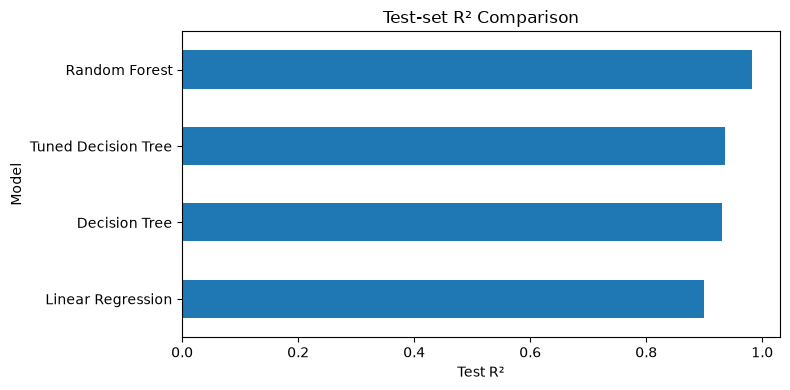

In [30]:
results_table["R²"].sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("Test R²")
plt.title("Test-set R² Comparison")
plt.tight_layout()
plt.show()

## 14. Select and Fit the Final Pipeline

Based on the recorded results, Random Forest is the current preferred candidate because it had lower prediction errors and higher test R² than the tuned Decision Tree. This selection should ideally be confirmed with cross-validation before production use.

A pipeline packages the model as one reusable object. This pipeline currently contains the estimator only; no scaling step is needed for a Random Forest.

In [31]:
final_pipeline = Pipeline([
    ("model", RandomForestRegressor(
        max_depth=10,
        min_samples_split=2,
        random_state=42
    ))
])

final_pipeline.fit(X_train, y_train)
print(final_pipeline)

Pipeline(steps=[('model',
                 RandomForestRegressor(max_depth=10, random_state=42))])


In [32]:
final_predictions = final_pipeline.predict(X_test)
final_results = evaluate_regression(final_pipeline, X_test, y_test)

print("Training R²:", round(final_pipeline.score(X_train, y_train), 4))
print("Testing R²:", round(final_results["R²"], 4))
pd.Series(final_results, name="Final Random Forest").round(4)

Training R²: 0.9964
Testing R²: 0.9815


MAE     0.6131
MSE     0.5842
RMSE    0.7644
R²      0.9815
Name: Final Random Forest, dtype: float64

### Interpretation

The final test metrics estimate how this fitted model performs on the held-out test subset. A strong test score is encouraging, but a single split can vary. Cross-validation can provide a more robust estimate. Avoid using the test set repeatedly to choose hyperparameters, because that can make the reported score optimistic.

## 15. Save the Final Pipeline

Save the trained pipeline with Joblib so another Python script or a FastAPI application can load it without retraining.

In [33]:
MODEL_PATH = "sales_prediction_pipeline.pkl"
joblib.dump(final_pipeline, MODEL_PATH)
print(f"Final pipeline saved to: {os.path.abspath(MODEL_PATH)}")

Final pipeline saved to: c:\Users\ACER\OIBSIP-GitHub\DataScience-Task5-SalesPrediction\sales_prediction_pipeline.pkl


## 16. Reload and Verify the Saved Model

Load the saved file and confirm the estimator and expected feature names.

In [34]:
loaded_model = joblib.load(MODEL_PATH)
print(loaded_model)
print("Expected features:", loaded_model.feature_names_in_)

Pipeline(steps=[('model',
                 RandomForestRegressor(max_depth=10, random_state=42))])
Expected features: ['TV' 'radio' 'newspaper']


## 17. Predict Sales for New Advertising Data

Provide one row with the same feature names and feature order used during training. The values should be in the same units as the training dataset.

In [35]:
new_data = pd.DataFrame({
    "TV": [150.0],
    "radio": [25.0],
    "newspaper": [20.0]
})

predicted_sales = loaded_model.predict(new_data)
print("Predicted Sales:", round(float(predicted_sales[0]), 2))

Predicted Sales: 15.17


## 18. Conclusion

This project explored sales prediction using TV, radio, and newspaper advertising expenditure. The workflow included data inspection, exploratory analysis, feature/target selection, a reproducible train-test split, regression model training, evaluation, Decision Tree tuning, and Random Forest comparison.

The recorded Random Forest test results were stronger than the tuned Decision Tree results. The final model is saved as `sales_prediction_pipeline.pkl` and can be loaded for predictions or integrated into a FastAPI application.

### Future Improvements
- Use cross-validation for model selection and hyperparameter tuning.
- Keep a final test set untouched until model selection is complete.
- Add input validation and error handling to the API.
- Document environment setup and usage in a GitHub README.